In [ ]:
import ee
import geemap
import xarray as xr

In [ ]:
!pip install xee
import xee

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 15.6 MB/s eta 0:00:00


In [ ]:
ee.Authenticate()
ee.Initialize(project='shining-axis-461118-t5',opt_url= 'https://earthengine-highvolume.googleapis.com')

In [ ]:
map=geemap.Map(basemap='SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(childr…

In [ ]:
roi=map.draw_last_feature.geometry()

In [ ]:
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          82.156013,
                          26.48037
                        ],
                        [
                          82.156013,
                          29.582976
                        ],
                        [
                          89.132743,
                          29.582976
                        ],
                        [
                          89.132743,
                          26.48037
                        ],
                        [
                          82.156013,
                          26.48037
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [ ]:
collection= ee.ImageCollection("ECMWF/ERA5/MONTHLY").select('mean_2m_air_temperature').filterDate('1980','2025')

In [ ]:
collection

In [ ]:
ds=xr.open_dataset(collection,engine='ee',crs='EPSG:4326', scale=0.27,geometry=roi)

In [ ]:
ds

<xarray.Dataset> Size: 611kB
Dimensions:                  (time: 486, lon: 26, lat: 12)
Coordinates:
  * time                     (time) datetime64[ns] 4kB 1980-01-01 ... 2020-06-01
  * lon                      (lon) float64 208B 82.51 82.78 ... 88.99 89.26
  * lat                      (lat) float64 96B 26.55 26.82 27.09 ... 29.25 29.52
Data variables:
    mean_2m_air_temperature  (time, lon, lat) float32 607kB ...
Attributes: (12/35)
    date_range:               [283996800000, 1590969600000]
    description:              <p>ERA5 is the fifth generation ECMWF atmospher...
    keywords:                 ['climate', 'copernicus', 'dewpoint', 'ecmwf', ...
    max_mirrored_version:     1594729140034009
    period:                   0
    product_tags:             ['wind', 'temperature', 'dewpoint', 'surface', ...
    ...                       ...
    visualization_3_bands:    u_component_of_wind_10m
    visualization_3_max:      30.0
    visualization_3_min:      0.0
    visualization_3_name:     Monthly mean u-component of wind at 10m
    visualization_3_palette:  #FFFFFF,#FFFF71,#DEFF00,#9EFF00,#77B038,#007E55...
    crs:                      EPSG:4326

In [ ]:
!pip install pymannkendall
import pymannkendall as mk

In [ ]:
def mk_test(img):
  test= mk.original_test(img)
  trend=test.trend
  trend_class= {'increasing':1,'decreasing':-1,'no_trend':0}
  trend_reclass=trend_class.get(trend,0)
  score=test.s
  pval= test.p
  return trend_reclass,score,pval

In [ ]:
change_trend, change_score, change_pval= xr.apply_ufunc(
    mk_test,
    ds.mean_2m_air_temperature,
    input_core_dims=[['time']],
    output_core_dims=[[],[],[]],
    dask='allowed',
    vectorize=True,
    output_dtypes=['int','float64','float64']
)


In [ ]:
change_trend=change_trend.rename('trend')
change_score= change_score.rename('score')*0.001
change_pval= change_pval.rename('p_value')


In [ ]:
import matplotlib.pyplot as plt


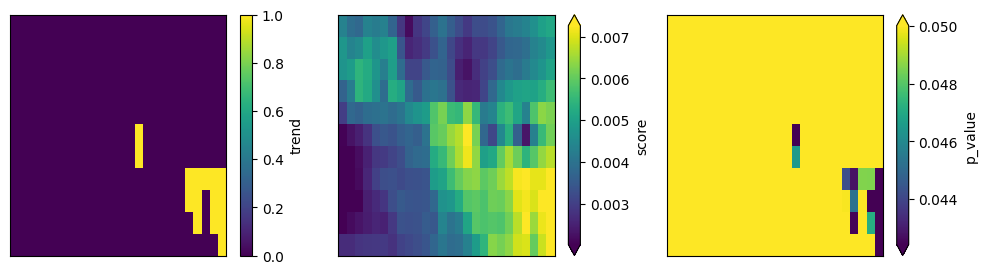

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(10,3))
plt.tight_layout()

change_trend.plot(x='lon',y='lat',ax=ax[0])
change_score.plot(x='lon',y='lat',ax=ax[1], robust=True)
change_pval.plot(x='lon',y='lat',ax=ax[2], robust=True,vmax=0.05)

for axis in ax:
  axis.set_ylabel('')
  axis.set_xlabel('')
  axis.set_xticks([])
  axis.set_yticks([])
#fig.subplots_adjust(wspace=0.4) # Adjust the width space between subplots

plt.savefig('mkchage.png',dpi=600,bbox_inches='tight')